# 07. Selector con machine learning: ¿SynthSeg o clásico?

El híbrido del notebook 06 decide con una regla fija (umbral de volumen). Aquí un **modelo de ML aprende la decisión** a partir de características de cada estudio que **no usan al experto**:

| Característica | Idea |
|---|---|
| `vol_SS`, `vol_Cl` | volumen ventricular de cada método |
| `log_ratio` | log(vol clásico / vol SynthSeg): grande si SynthSeg subestima |
| `dice_SS_Cl` | acuerdo entre ambos métodos |
| `frac_SS_en_Cl`, `frac_Cl_en_SS` | cuánto de cada máscara cae dentro de la otra |
| `vol_SS_csf` | LCR externo según SynthSeg (si confunde ventrículo con LCR, crece) |
| `ratio_SS_cerebro`, `ratio_Cl_cerebro` | volumen ventricular relativo al cerebro |
| `n_comp_Cl` | componentes del clásico (muchas = surcos) |

**Objetivo**: clasificar si el clásico supera a SynthSeg en ese estudio. Los errores se ponderan por la diferencia de Dice, para que importen más los casos donde equivocarse cuesta mucho.

**Modelos**: regresión logística y Random Forest, con la misma validación cruzada 5-fold x 10 por paciente del notebook 06.

Salidas en `outputs/figuras_07_ml/`. Las máscaras del clásico se guardan en `outputs/predicciones/Clasico/` (las reutilizan los notebooks 04 y 08).

In [2]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import shutil
import time
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

from src.io import list_scans, load, load_seg
from src.paths import OUTPUTS
import src.clasico as clasico

FIG_DIR = OUTPUTS / "figuras_07_ml"
if FIG_DIR.exists():
    shutil.rmtree(FIG_DIR)
FIG_DIR.mkdir(parents=True)
PRED_CL = OUTPUTS / "predicciones" / "Clasico"
PRED_CL.mkdir(parents=True, exist_ok=True)
FEAT_CSV = OUTPUTS / "predicciones" / "features_selector.csv"

def guardar(nombre, dpi=110):
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

SEED = 42
K, REPETICIONES = 5, 10
FS_VENT = [4, 5, 43, 44]
FS_CSF = [24]
RECALCULAR = False
scans = list_scans()

## 1. Características por estudio
Se calculan una vez y se guardan en `features_selector.csv`.

In [3]:
def dice(a, b):
    d = a.sum() + b.sum()
    return 2 * (a & b).sum() / d if d else np.nan


def hd95(a, b, zooms):
    if a.sum() == 0 or b.sum() == 0:
        return np.nan
    ba, bb = a & ~ndi.binary_erosion(a), b & ~ndi.binary_erosion(b)
    da = ndi.distance_transform_edt(~bb, sampling=zooms)[ba]
    db = ndi.distance_transform_edt(~ba, sampling=zooms)[bb]
    return np.percentile(np.concatenate([da, db]), 95)


def caracteristicas(s):
    img_n = nib.as_closest_canonical(nib.load(s / "eT1W_FFE_SVR.nii.gz"))
    img, zooms = img_n.get_fdata(), img_n.header.get_zooms()[:3]
    g = load_seg(s / "segmentation" / "gt.nii.gz")[0] == 4
    p = s / "segmentation" / "synthseg.nii.gz"
    if not p.exists():
        return None
    ssl = np.asarray(nib.as_closest_canonical(nib.load(p)).dataobj).astype(int)
    if ssl.shape != g.shape:
        return None
    ss = np.isin(ssl, FS_VENT)

    pc = PRED_CL / f"{s.parent.name}_{s.name}.nii.gz"
    if pc.exists() and not RECALCULAR:
        cl = np.asarray(nib.load(pc).dataobj).astype(bool)
    else:
        box = clasico.crop_box(img)
        cl = np.zeros(g.shape, bool)
        cl[box] = clasico.segmentar(img[box], zooms)[0]
        nib.save(nib.Nifti1Image(cl.astype(np.uint8), img_n.affine), pc)

    box = clasico.crop_box(img)
    brain = np.zeros(g.shape, bool)
    brain[box] = clasico.brain_mask(img[box])
    ml = float(np.prod(zooms)) / 1000
    v_ss, v_cl, v_br = ss.sum() * ml, cl.sum() * ml, max(brain.sum() * ml, 1)
    inter = (ss & cl).sum() * ml
    return {
        "subject": s.parent.name, "scan": s.name, "vol_gt": g.sum() * ml,
        "vol_SS": v_ss, "vol_Cl": v_cl,
        "log_ratio": np.log((v_cl + 1) / (v_ss + 1)),
        "dice_SS_Cl": dice(ss, cl),
        "frac_SS_en_Cl": inter / v_ss if v_ss else 0,
        "frac_Cl_en_SS": inter / v_cl if v_cl else 0,
        "vol_SS_csf": np.isin(ssl, FS_CSF).sum() * ml,
        "ratio_SS_cerebro": v_ss / v_br, "ratio_Cl_cerebro": v_cl / v_br,
        "n_comp_Cl": ndi.label(cl)[1],
        "dice_SynthSeg": dice(ss, g), "dice_Clasico": dice(cl, g),
        "hd95_SynthSeg": hd95(ss, g, zooms), "hd95_Clasico": hd95(cl, g, zooms),
    }


if FEAT_CSV.exists() and not RECALCULAR:
    df = pd.read_csv(FEAT_CSV)
    print("Reutilizando", FEAT_CSV)
else:
    filas = []
    for s in scans:
        t0 = time.time()
        f = caracteristicas(s)
        if f is not None:
            filas.append(f)
            print(f"{s.parent.name}/{s.name} ({time.time() - t0:.0f}s)")
    df = pd.DataFrame(filas)
    df.to_csv(FEAT_CSV, index=False)

df["vol_SynthSeg"], df["vol_Clasico"] = df.vol_SS, df.vol_Cl
df["rango"] = pd.cut(df.vol_gt, [0, 30, 150, np.inf], labels=["pequeño", "mediano", "grande"])
df["y"] = (df.dice_Clasico > df.dice_SynthSeg).astype(int)
df["peso"] = (df.dice_Clasico - df.dice_SynthSeg).abs() + 0.02
FEATS = ["vol_SS", "vol_Cl", "log_ratio", "dice_SS_Cl", "frac_SS_en_Cl", "frac_Cl_en_SS",
         "vol_SS_csf", "ratio_SS_cerebro", "ratio_Cl_cerebro", "n_comp_Cl"]
print(len(df), "estudios | clásico mejor en", df.y.sum())
display(df[["subject", "vol_gt"] + FEATS + ["dice_SynthSeg", "dice_Clasico", "y"]].round(3).head())

sub_001/scan_01 (26s)
sub_003/scan_01 (42s)
sub_004/scan_01 (56s)
sub_005/scan_01 (44s)
sub_006/scan_01 (65s)
sub_007/scan_01 (54s)
sub_009/scan_01 (59s)
sub_010/scan_01 (44s)
sub_011/scan_01 (59s)
sub_012/scan_01 (56s)
sub_013/scan_01 (54s)
sub_015/scan_01 (67s)
sub_016/scan_01 (59s)
sub_017/scan_01 (53s)
sub_018/scan_01 (38s)
sub_019/scan_01 (17s)
sub_019/scan_02 (20s)
sub_020/scan_01 (19s)
sub_021/scan_01 (20s)
sub_022/scan_01 (19s)
sub_023/scan_01 (18s)
sub_024/scan_01 (17s)
sub_025/scan_01 (18s)
sub_026/scan_01 (14s)
sub_028/scan_01 (16s)
sub_029/scan_01 (16s)
sub_030/scan_01 (16s)
sub_031/scan_01 (16s)
sub_032/scan_01 (17s)
sub_033/scan_01 (19s)
sub_035/scan_01 (19s)
sub_036/scan_01 (23s)
sub_037/scan_01 (20s)
sub_038/scan_01 (21s)
sub_039/scan_01 (19s)
sub_039/scan_02 (15s)
sub_040/scan_01 (15s)
sub_041/scan_01 (17s)
sub_042/scan_01 (18s)
sub_043/scan_01 (17s)
sub_044/scan_01 (19s)
sub_045/scan_01 (17s)
sub_046/scan_01 (15s)
sub_047/scan_01 (18s)
sub_048/scan_01 (22s)
45 estudio

,subject,vol_gt,vol_SS,vol_Cl,log_ratio,dice_SS_Cl,frac_SS_en_Cl,frac_Cl_en_SS,vol_SS_csf,ratio_SS_cerebro,ratio_Cl_cerebro,n_comp_Cl,dice_SynthSeg,dice_Clasico,y
0,sub_001,15.367,14.793,15.743,0.058,0.628,0.648,0.609,201.768,0.011,0.012,1,0.902,0.628,0
1,sub_003,67.288,68.052,88.082,0.255,0.781,0.896,0.692,256.920,0.048,0.063,1,0.977,0.779,0
2,sub_004,278.857,207.468,298.492,0.362,0.777,0.948,0.659,249.982,0.139,0.199,1,0.839,0.907,1
3,sub_005,82.498,74.375,93.844,0.230,0.838,0.948,0.752,205.578,0.058,0.073,1,0.911,0.863,0
4,sub_006,287.589,118.360,124.101,0.047,0.467,0.479,0.456,290.357,0.091,0.095,1,0.558,0.538,0


## 2. Exploración: ¿las características separan las clases?

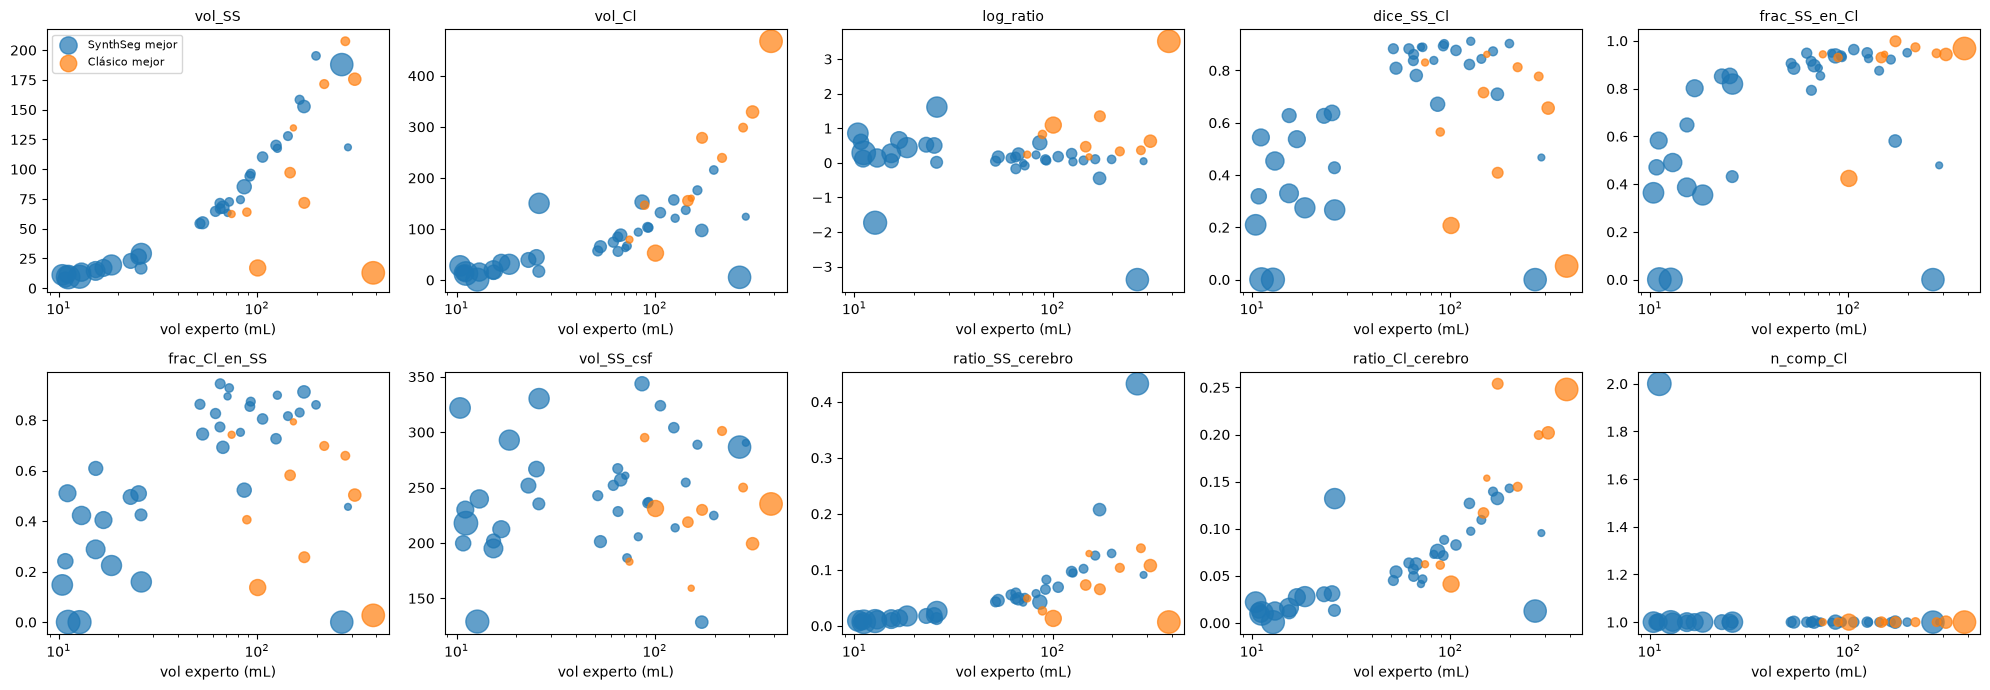

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for a, f in zip(axes.flat, FEATS):
    for y, c, lab in [(0, "tab:blue", "SynthSeg mejor"), (1, "tab:orange", "Clásico mejor")]:
        sub = df[df.y == y]
        a.scatter(sub.vol_gt, sub[f], s=12 + 300 * sub.peso, color=c, alpha=0.7, label=lab)
    a.set_xscale("log"); a.set_title(f, fontsize=10); a.set_xlabel("vol experto (mL)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); guardar("exploracion_features"); plt.show()

## 3. Validación cruzada 5-fold x 10 (por paciente)
Se comparan: SynthSeg, clásico, regla H1 (umbral calibrado en train), regresión logística, Random Forest y el **oráculo** (elige siempre el mejor; límite superior).

In [5]:
def particion_kfold(df, k, seed):
    pac = df.groupby("subject").agg(vol=("vol_gt", "max")).reset_index()
    pac["rango"] = pd.cut(pac.vol, [0, 30, 150, np.inf], labels=["p", "m", "g"])
    r = np.random.default_rng(seed)
    fold = {}
    for _, g_ in pac.groupby("rango", observed=True):
        ids = list(g_.subject)
        r.shuffle(ids)
        for i, s in enumerate(ids):
            fold[s] = i % k
    return df.subject.map(fold)


def regla_h1(tr, te):
    mejor_u, mejor_d = None, -1
    for u in [60, 80, 100, 125, 150, 175, 200, 250, 300]:
        d = np.where(tr.vol_Cl > u, tr.dice_Clasico, tr.dice_SynthSeg).mean()
        if d > mejor_d + 1e-9:
            mejor_u, mejor_d = u, d
    return (te.vol_Cl > mejor_u).astype(int).values


def modelo(nombre):
    if nombre == "LogReg":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000))
    return RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=2,
                                  class_weight="balanced", random_state=SEED)


SELECTORES = ["H1", "LogReg", "RandomForest"]
res = []
for rep in range(REPETICIONES):
    folds = particion_kfold(df, K, SEED + rep)
    for k in range(K):
        tr, te = df[folds != k], df[folds == k]
        el = {"H1": regla_h1(tr, te)}
        for n in ["LogReg", "RandomForest"]:
            if tr.y.nunique() < 2:
                el[n] = np.full(len(te), tr.y.iloc[0])
                continue
            m = modelo(n)
            kw = {"logisticregression__sample_weight": tr.peso} if n == "LogReg" else {"sample_weight": tr.peso}
            m.fit(tr[FEATS], tr.y, **kw)
            el[n] = m.predict(te[FEATS])
        for i, (_, r) in enumerate(te.iterrows()):
            fila = {"rep": rep, "fold": k, "subject": r.subject, "scan": r.scan}
            for n in SELECTORES:
                fila[f"elige_{n}"] = int(el[n][i])
            res.append(fila)
cv = pd.DataFrame(res)
cv.to_csv(FIG_DIR / "cv_elecciones.csv", index=False)

pc = cv.groupby(["subject", "scan"])[[f"elige_{n}" for n in SELECTORES]].mean().reset_index()
pc = df.merge(pc, on=["subject", "scan"])
for n in SELECTORES:
    p = pc[f"elige_{n}"]
    pc[f"dice_{n}"] = p * pc.dice_Clasico + (1 - p) * pc.dice_SynthSeg
    pc[f"vol_{n}"] = p * pc.vol_Clasico + (1 - p) * pc.vol_SynthSeg
pc["dice_Oraculo"] = pc[["dice_SynthSeg", "dice_Clasico"]].max(axis=1)
pc["vol_Oraculo"] = np.where(pc.dice_Clasico > pc.dice_SynthSeg, pc.vol_Clasico, pc.vol_SynthSeg)
pc.to_csv(FIG_DIR / "cv_por_caso.csv", index=False)
print("Nota: con 10 repeticiones, dice_<selector> es el promedio esperado sobre las particiones.")

Nota: con 10 repeticiones, dice_<selector> es el promedio esperado sobre las particiones.


## 4. Resultados

In [6]:
METODOS = ["SynthSeg", "Clasico", "H1", "LogReg", "RandomForest", "Oraculo"]


def ic(x, n=5000):
    r = np.random.default_rng(SEED)
    x = np.asarray(x)
    m = [r.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])


rows = []
for grupo, sub in [("total", pc)] + list(pc.groupby("rango", observed=True)):
    for n in METODOS:
        lo, hi = ic(sub[f"dice_{n}"])
        d = sub[f"vol_{n}"] - sub.vol_gt
        err = (d / sub.vol_gt * 100).abs()
        rows.append({"rango": grupo, "metodo": n, "n": len(sub), "dice_media": sub[f"dice_{n}"].mean(),
                     "IC95_low": lo, "IC95_high": hi, "dice_min": sub[f"dice_{n}"].min(),
                     "err_vol_abs_mediana_%": err.median(), "sesgo_ml": d.mean(), "LoA_ml": 1.96 * d.std(),
                     "casos_dice<0.5": int((sub[f"dice_{n}"] < 0.5).sum())})
resumen = pd.DataFrame(rows)
resumen.to_csv(FIG_DIR / "resultados_selector.csv", index=False)
display(resumen.round(3))
display(resumen.pivot(index="metodo", columns="rango", values="dice_media").loc[METODOS].round(3))

print("Wilcoxon pareado vs SynthSeg:")
for n in ["H1", "LogReg", "RandomForest"]:
    x, y = pc[f"dice_{n}"], pc.dice_SynthSeg
    try:
        p = wilcoxon(x, y).pvalue
    except ValueError:
        p = np.nan
    print(f"  {n}: diferencia media {np.mean(x - y):+.3f}, p = {p:.4f}")

,rango,metodo,n,dice_media,IC95_low,IC95_high,dice_min,err_vol_abs_mediana_%,sesgo_ml,LoA_ml,casos_dice<0.5
0,total,SynthSeg,45,0.849,0.790,0.896,0.062,7.998,-27.250,128.178,2
1,total,Clasico,45,0.669,0.588,0.745,0.000,21.239,4.380,114.581,10
2,total,H1,45,0.874,0.829,0.908,0.197,7.189,-6.315,75.881,1
3,total,LogReg,45,0.858,0.804,0.901,0.197,7.041,-1.685,84.121,2
4,total,RandomForest,45,0.856,0.804,0.897,0.197,7.041,-0.154,83.759,2
5,total,Oraculo,45,0.891,0.862,0.918,0.558,5.752,-0.743,72.880,0
6,pequeño,SynthSeg,14,0.886,0.851,0.915,0.741,5.756,-0.800,5.801,0
7,pequeño,Clasico,14,0.381,0.271,0.488,0.000,50.775,14.326,64.785,9
8,pequeño,H1,14,0.886,0.851,0.915,0.741,5.756,-0.800,5.801,0
9,pequeño,LogReg,14,0.840,0.734,0.910,0.243,5.756,7.849,65.868,1


rango,grande,mediano,pequeño,total
metodo,,,,
SynthSeg,0.735,0.887,0.886,0.849
Clasico,0.748,0.827,0.381,0.669
H1,0.834,0.887,0.886,0.874
LogReg,0.834,0.885,0.840,0.858
RandomForest,0.846,0.870,0.844,0.856
Oraculo,0.853,0.916,0.886,0.891


Wilcoxon pareado vs SynthSeg:
  H1: diferencia media +0.024, p = 0.1730
  LogReg: diferencia media +0.009, p = 0.6832
  RandomForest: diferencia media +0.007, p = 0.8261


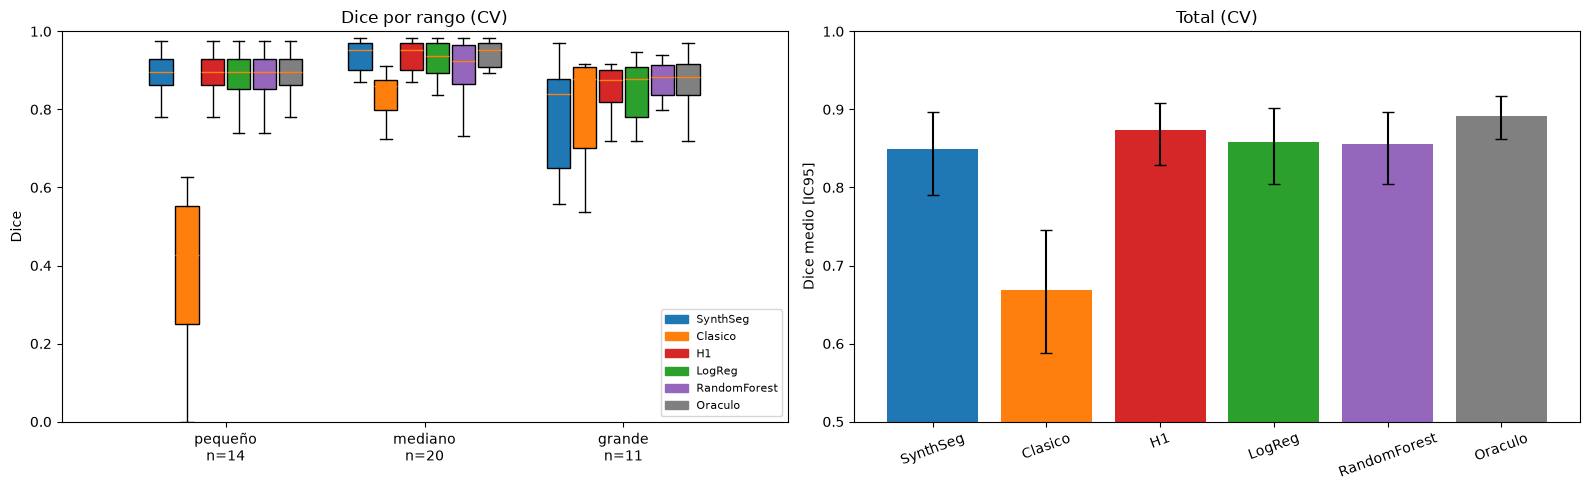

In [7]:
col = {"SynthSeg": "tab:blue", "Clasico": "tab:orange", "H1": "tab:red", "LogReg": "tab:green",
       "RandomForest": "tab:purple", "Oraculo": "gray"}
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
rangos = list(pc.rango.cat.categories)
w = 0.13
for i, n in enumerate(METODOS):
    pos = np.arange(len(rangos)) + (i - 2.5) * w
    bp = ax[0].boxplot([pc.loc[pc.rango == r, f"dice_{n}"] for r in rangos], positions=pos,
                       widths=w * 0.9, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col[n])
ax[0].set_xticks(range(len(rangos)))
ax[0].set_xticklabels([f"{r}\nn={(pc.rango == r).sum()}" for r in rangos])
ax[0].set_ylim(0, 1); ax[0].set_ylabel("Dice"); ax[0].set_title("Dice por rango (CV)")
ax[0].legend([plt.Rectangle((0, 0), 1, 1, color=col[n]) for n in METODOS], METODOS, fontsize=8)

med = resumen[resumen.rango == "total"].set_index("metodo").loc[METODOS]
ax[1].bar(METODOS, med.dice_media, color=[col[n] for n in METODOS],
          yerr=[med.dice_media - med.IC95_low, med.IC95_high - med.dice_media], capsize=4)
ax[1].set_ylim(0.5, 1); ax[1].set_ylabel("Dice medio [IC95]"); ax[1].set_title("Total (CV)")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); guardar("resultados_selector"); plt.show()

## 5. Importancia de características (modelo entrenado con todos los casos)
Solo para interpretar; no es una evaluación.

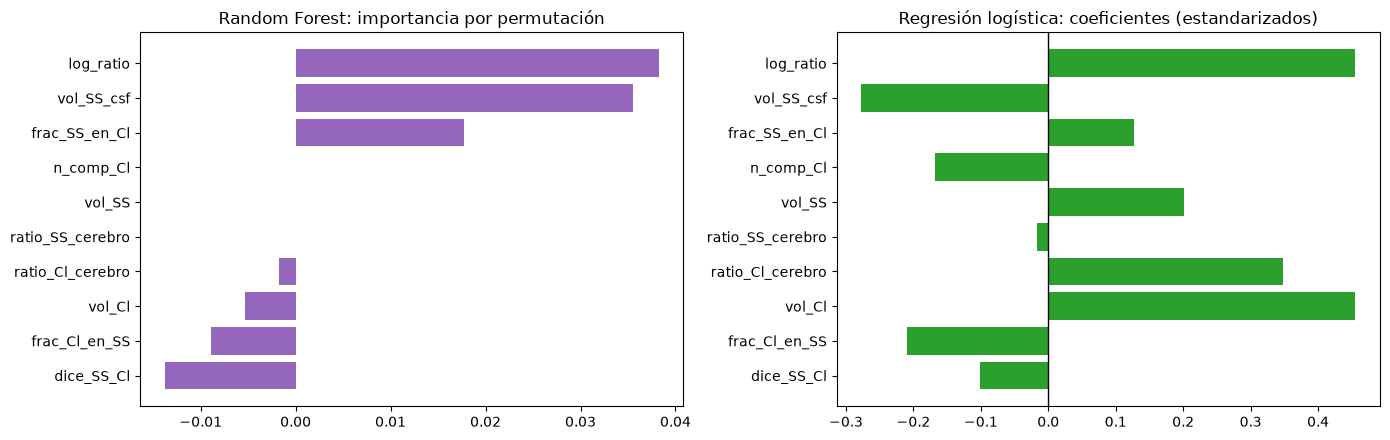

In [8]:
rf = modelo("RandomForest").fit(df[FEATS], df.y, sample_weight=df.peso)
lr = modelo("LogReg").fit(df[FEATS], df.y, logisticregression__sample_weight=df.peso)
pi = permutation_importance(rf, df[FEATS], df.y, n_repeats=50, random_state=SEED)
imp = pd.DataFrame({"feature": FEATS, "RF_permutacion": pi.importances_mean,
                    "RF_gini": rf.feature_importances_,
                    "LogReg_coef": lr.named_steps["logisticregression"].coef_[0]}).sort_values("RF_permutacion")
imp.to_csv(FIG_DIR / "importancia_features.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(imp.feature, imp.RF_permutacion, color="tab:purple"); ax[0].set_title("Random Forest: importancia por permutación")
ax[1].barh(imp.feature, imp.LogReg_coef, color="tab:green"); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Regresión logística: coeficientes (estandarizados)")
plt.tight_layout(); guardar("importancia_features"); plt.show()

## 6. Casos donde los selectores difieren

In [9]:
dif = pc[(pc.elige_H1.round() != pc.elige_RandomForest.round()) | (pc.elige_LogReg.round() != pc.elige_RandomForest.round()) | (pc.y == 1)]
display(dif.sort_values("vol_gt")[["subject", "scan", "vol_gt", "vol_SS", "vol_Cl", "dice_SynthSeg", "dice_Clasico",
                                    "elige_H1", "elige_LogReg", "elige_RandomForest", "dice_RandomForest"]].round(2))
print("Archivos en", FIG_DIR)
for f in sorted(FIG_DIR.iterdir()):
    print(" ", f.name)

,subject,scan,vol_gt,vol_SS,vol_Cl,dice_SynthSeg,dice_Clasico,elige_H1,elige_LogReg,elige_RandomForest,dice_RandomForest
41,sub_045,scan_01,26.08,29.21,150.30,0.89,0.24,0.0,1.0,0.9,0.31
38,sub_042,scan_01,74.48,62.33,79.27,0.87,0.89,0.0,0.0,0.0,0.87
6,sub_009,scan_01,86.20,85.26,152.83,0.96,0.67,0.0,0.0,0.8,0.73
33,sub_038,scan_01,88.88,63.94,146.68,0.67,0.72,0.0,0.1,0.2,0.68
19,sub_022,scan_01,100.77,17.05,52.75,0.20,0.58,0.0,0.0,0.0,0.20
21,sub_024,scan_01,124.69,119.99,156.95,0.96,0.84,0.0,0.6,0.9,0.85
28,sub_032,scan_01,146.87,97.08,155.29,0.79,0.91,0.0,0.4,0.1,0.80
7,sub_010,scan_01,152.60,134.68,160.25,0.87,0.88,0.0,0.9,0.4,0.88
27,sub_031,scan_01,164.04,158.32,175.80,0.96,0.89,0.9,0.2,0.3,0.94
36,sub_040,scan_01,172.50,152.65,97.22,0.88,0.68,0.0,0.6,0.0,0.88


Archivos en C:\Users\Usuario\Desktop\Vida_Academica\2026-II\FIB\hykid\outputs\figuras_07_ml
  cv_elecciones.csv
  cv_por_caso.csv
  exploracion_features.png
  importancia_features.csv
  importancia_features.png
  resultados_selector.csv
  resultados_selector.png
